# Avaliação de Modelos de Previsão Probabilística e Pontual em Dados Climáticos via sktime

Modelos escolhidos: Naive, AutoARIMA, Theta, Prophet, ExpSmoothing + NaiveVariance.

Série utilizada: https://zenodo.org/records/5184708

Inspirações: https://www.sciencedirect.com/science/article/pii/S0169207021001187


https://www.sciencedirect.com/science/article/pii/S0169207019301128


https://www.sktime.net/en/latest/examples/01_forecasting.html

Instalando o sktime

In [ ]:
!pip install sktime prophet pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.3/36.3 MB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.5/151.5 kB 7.6 MB/s eta 0:00:00


Importando bibliotecas

In [ ]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import zipfile
import warnings
import numpy as np

from urllib.request import urlretrieve
from sktime.forecasting.base import ForecastingHorizon
from sktime.performance_metrics.forecasting.probabilistic import PinballLoss
from sktime.performance_metrics.forecasting import MeanAbsoluteScaledError
from sktime.performance_metrics.forecasting import MeanSquaredError


from sktime.forecasting.naive import NaiveForecaster, NaiveVariance
from sktime.forecasting.theta import ThetaForecaster
from sktime.forecasting.arima import AutoARIMA
from sktime.forecasting.fbprophet import Prophet
from sktime.forecasting.exp_smoothing import ExponentialSmoothing

from sktime.split import temporal_train_test_split


Baixando o arquivo da série temporal

In [ ]:
url = "https://zenodo.org/record/5184708/files/oikolab_weather_dataset.zip?download=1"
caminhoZip = "oikolab_weather_dataset.zip"
nomeArquivoTsf = "oikolab_weather_dataset.tsf"

# baixando arquivo caso precise
if not os.path.exists(caminhoZip):
    urlretrieve(url, caminhoZip)

# extraindo arquivo
with zipfile.ZipFile(caminhoZip, 'r') as arquivoZip:
    arquivoZip.extractall(".")


In [ ]:
# função auxiliar para ler arquivo em tsf
def lerTsf(caminhoArquivo):
    metadados = {}
    dados = []

    with open(caminhoArquivo, 'r', encoding='cp1252') as arquivo:
        for linha in arquivo:
            linha = linha.strip()

            if not linha or linha.startswith("#"):
                continue

            # processa metadados
            if linha.startswith("@"):
                if linha.startswith("@data"):
                    continue

                partes = linha.split()
                if partes[0] == "@attribute":
                    # cria a chave 'colunas' no dicionário se não existir
                    if 'colunas' not in metadados:
                        metadados['colunas'] = {}
                    metadados['colunas'][partes[1]] = partes[2]
                else:
                    chave = partes[0][1:]
                    metadados[chave] = partes[1]

            # processa dados reais (linhas separadas por :)
            else:
                partes = linha.split(":")
                valoresTexto = partes[-1].split(",")
                # converte texto para float e trata dados faltantes (?)
                valoresSerie = [float(x) if x != "?" else None for x in valoresTexto]

                dados.append(partes[:-1] + [valoresSerie])

    # cria o DataFrame bruto
    nomesColunas = list(metadados.get('colunas', {}).keys()) + ['valoresSerie']
    dfBruto = pd.DataFrame(dados, columns=nomesColunas)

    return dfBruto, metadados.get('frequency'), metadados.get('horizon')

Organizando DataFrame

Dimensões do Dataset: (100057, 8)
Dados:


,Temperatura,PontoOrvalho,VelocidadeVento,Pressao,UmidadeRelativa,RadiacaoSolar,RadiacaoTermica,CoberturaNuvens
2010-01-01 00:00:00,18.26,16.39,2.60,101046.38,0.89,287.01,408.35,1.0
2010-01-01 01:00:00,18.67,16.29,2.91,101037.96,0.86,360.79,411.02,1.0
2010-01-01 02:00:00,18.16,15.89,3.26,101017.26,0.87,291.54,410.67,1.0
2010-01-01 03:00:00,18.46,15.33,3.17,101022.56,0.82,357.11,410.95,1.0
2010-01-01 04:00:00,18.53,15.11,2.95,100940.03,0.80,459.91,410.00,0.9


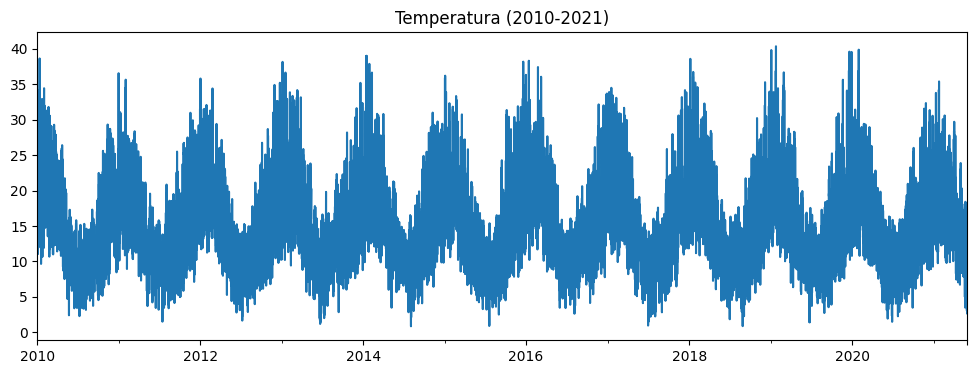

In [ ]:
dfBruto, frequencia, horizonte = lerTsf(nomeArquivoTsf)
dataInicio = pd.Timestamp("2010-01-01 00:00:00")
dadosFormatados = {}

for indice, linha in dfBruto.iterrows():
    codigoVariavel = linha.iloc[0]
    valores = linha['valoresSerie']
    dadosFormatados[codigoVariavel] = valores

dfFinal = pd.DataFrame(dadosFormatados)

# cria o índice de tempo (Hora em Hora)
dfFinal.index = pd.date_range(start=dataInicio, periods=len(dfFinal), freq='h')

# renomeando colunas
mapaNomes = {
    'T1': 'Temperatura',
    'T2': 'PontoOrvalho',
    'T3': 'VelocidadeVento',
    'T4': 'Pressao',
    'T5': 'UmidadeRelativa',
    'T6': 'RadiacaoSolar',
    'T7': 'RadiacaoTermica',
    'T8': 'CoberturaNuvens'
}

dfFinal = dfFinal.rename(columns=mapaNomes)
print(f'Dimensões do Dataset: {dfFinal.shape}')
print('Dados:')
display(dfFinal.head())

# plota grafico da temperatura para confirmar
dfFinal['Temperatura'].plot(figsize=(12, 4), title='Temperatura (2010-2021)')
plt.show()

Definindo o período de teste e o horizonte de previsão

In [ ]:
# o período utilizado foi de 32 dias, aproximadamente 768 horas e foi dividido em treino 25 dias (600) e o teste última semana, 168 horas.
warnings.filterwarnings('ignore')

# filtra para pegar apenas os últimos 768 registros primeiro
serie_janela = dfFinal['Temperatura'].iloc[-768:]

# divide: 168 para teste e o restante (600) para treino
y_treino, y_teste = temporal_train_test_split(serie_janela, test_size=168)

# horizonte de Previsão
fh = ForecastingHorizon(y_teste.index, is_relative=False)

Definindo modelos

In [ ]:
modelos = {
    # benchMark
    "Naive": NaiveForecaster(strategy="last", sp=24),
    # estático clássico
    "Theta": ThetaForecaster(sp=24),
    "AutoARIMA": AutoARIMA(sp=24, suppress_warnings=True, n_jobs=-1),
    # machine learning
    "Prophet": Prophet(freq='h', daily_seasonality=True, yearly_seasonality=False),
    # modelo compsto
    "ExpSmoothing + Var": NaiveVariance(
        ExponentialSmoothing(trend=None, seasonal="add", sp=24, initialization_method="estimated")
    )
}

# métricas inspiradas nas competições M4 e M5
metrica_mase = MeanAbsoluteScaledError(sp=24)  # precisão da Linha (M4)
metrica_rmse = MeanSquaredError(square_root=True)
metrica_pinball = PinballLoss(score_average=True)  # precisão do Intervalo (M5)



# registro dos resultados
preds_modelos = {}
intervalos_modelos = {}
resultados_modelos = {}



Naive

In [ ]:
modelo = modelos['Naive']
modelo.fit(y_treino)

y_pred = modelo.predict(fh)
intervalos = modelo.predict_interval(fh, coverage=0.9)

mase = metrica_mase(y_true=y_teste, y_pred=y_pred, y_train=y_treino)
rmse = metrica_rmse(y_true=y_teste, y_pred=y_pred)
pinball = None
try:
    pinball = metrica_pinball(y_true=y_teste, y_pred=intervalos)
except:
    pinball = np.nan

erro_abs = (y_teste - y_pred).abs()

rmse_24 = MeanSquaredError(square_root=True)(
    y_true=y_teste.iloc[:24],
    y_pred=y_pred.iloc[:24]
)

rmse_168 = MeanSquaredError(square_root=True)(
    y_true=y_teste,
    y_pred=y_pred
)


# salvando resultados
preds_modelos['Naive'] = y_pred
intervalos_modelos['Naive'] = intervalos
resultados_modelos['Naive'] = {
    'MASE': mase,
    'RMSE': rmse,
    'RMSE_24h': rmse_24,
    'RMSE_168h': rmse_168,
    'Pinball_90': pinball
}


print(f'{'Naive':<20} | MASE {mase:.4f} | Pinball {pinball:.4f} | RMSE {rmse:.4f}')

Naive                | MASE 3.2149 | Pinball 0.5334 | RMSE 6.3159


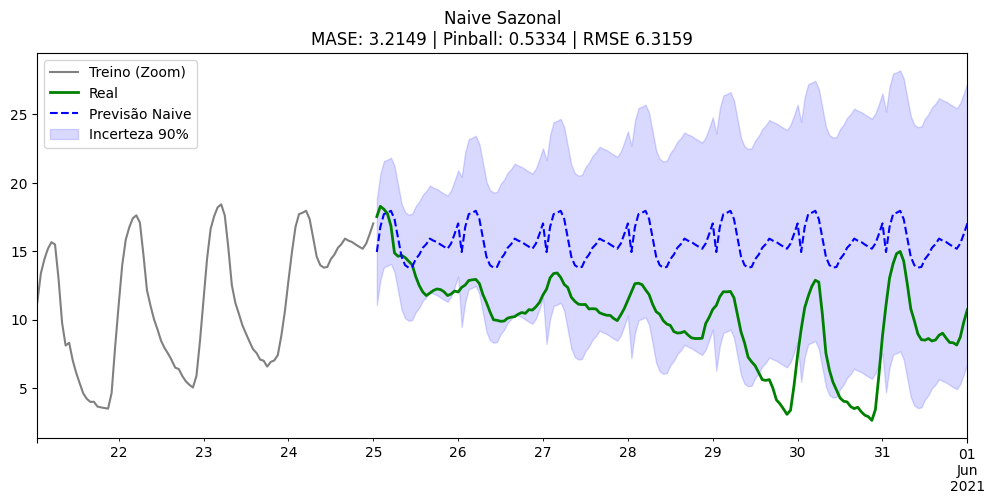

In [ ]:
plt.figure(figsize=(12, 5))
y_treino.iloc[-96:].plot(label='Treino (Zoom)', color='gray')
y_teste.plot(label='Real', color='green', linewidth=2)
y_pred.plot(label='Previsão Naive', color='blue', linestyle='--')
plt.fill_between(intervalos.index,
                 intervalos[(y_treino.name, 0.9, 'lower')],
                 intervalos[(y_treino.name, 0.9, 'upper')],
                 color='blue', alpha=0.15, label='Incerteza 90%' )
plt.title(f'Naive Sazonal\nMASE: {mase:.4f} | Pinball: {pinball:.4f} | RMSE {rmse:.4f}')
plt.legend()
plt.show()

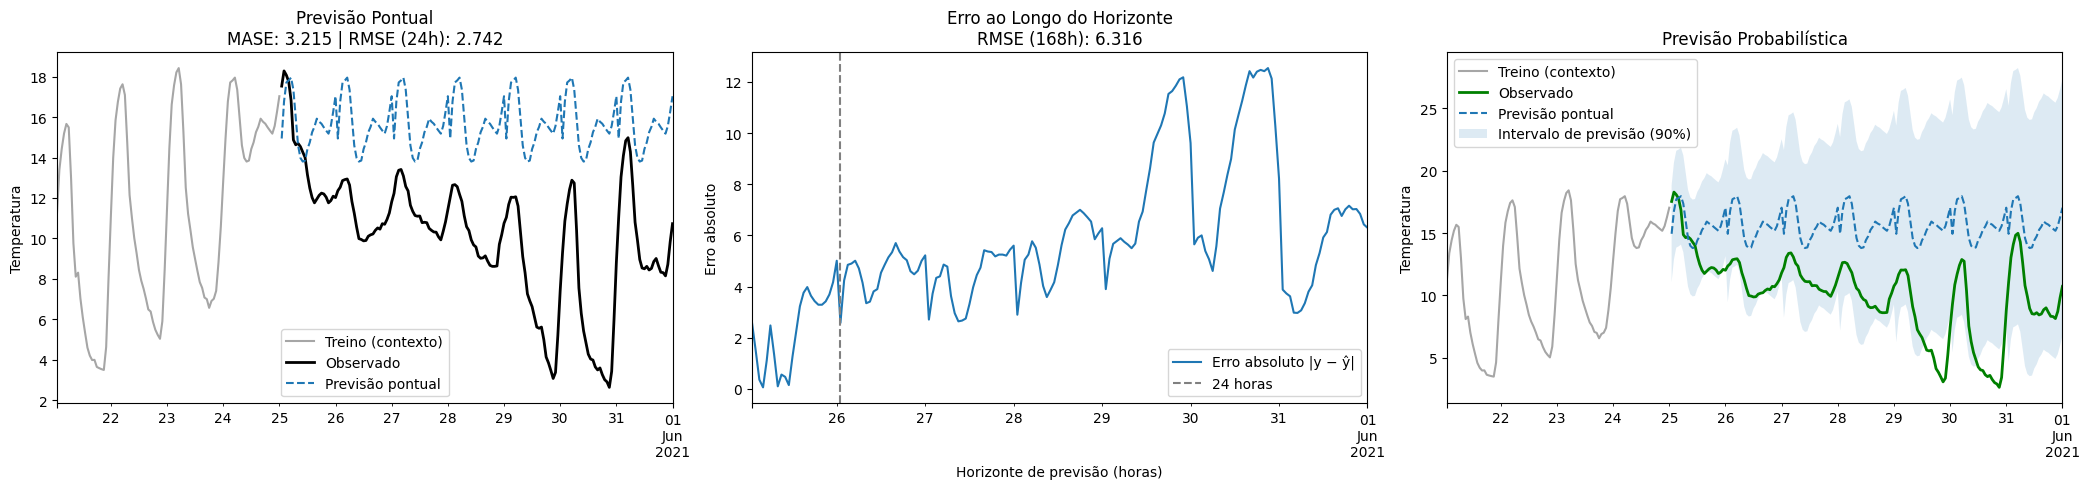

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))

# previsão pontual
y_treino.iloc[-96:].plot(
    ax=axes[0],
    label="Treino (contexto)",
    color="gray",
    alpha=0.7
)

y_teste.plot(
    ax=axes[0],
    label="Observado",
    color="black",
    linewidth=2
)

y_pred.plot(
    ax=axes[0],
    label="Previsão pontual",
    linestyle="--"
)

axes[0].set_title(
    "Previsão Pontual\n"
    f"MASE: {mase:.3f} | RMSE (24h): {rmse_24:.3f}"
)

axes[0].set_ylabel("Temperatura")
axes[0].legend(loc="best")


# erro absoluto por horizonte

erro_abs.plot(
    ax=axes[1],
    label="Erro absoluto |y − ŷ|"
)

axes[1].axvline(
    y_teste.index[24],
    linestyle="--",
    color="gray",
    label="24 horas"
)



axes[1].set_title(
    "Erro ao Longo do Horizonte\n"
    f"RMSE (168h): {rmse_168:.3f}"
)

axes[1].set_ylabel("Erro absoluto")
axes[1].set_xlabel("Horizonte de previsão (horas)")
axes[1].legend(loc="best")

# previsão probabilística
y_treino.iloc[-96:].plot(
    ax=axes[2],
    label="Treino (contexto)",
    color="gray",
    alpha=0.7
)

y_teste.plot(
    ax=axes[2],
    label="Observado",
    color="green",
    linewidth=2
)

y_pred.plot(
    ax=axes[2],
    label="Previsão pontual",
    linestyle="--"
)

axes[2].fill_between(
    intervalos.index,
    intervalos[(y_treino.name, 0.9, "lower")],
    intervalos[(y_treino.name, 0.9, "upper")],
    alpha=0.15,
    label="Intervalo de previsão (90%)"
)

axes[2].set_title("Previsão Probabilística")
axes[2].set_ylabel("Temperatura")
axes[2].legend(loc="best")

plt.tight_layout()
plt.show()


Theta

In [ ]:
modelo = modelos['Theta']
modelo.fit(y_treino)

y_pred = modelo.predict(fh)

intervalos = modelo.predict_interval(fh, coverage=0.9)

mase = metrica_mase(y_true=y_teste, y_pred=y_pred, y_train=y_treino)
rmse = metrica_rmse(y_true=y_teste, y_pred=y_pred)
pinball = None
try:
    pinball = metrica_pinball(y_true=y_teste, y_pred=intervalos)
except:
    pinball = np.nan

erro_abs = (y_teste - y_pred).abs()

rmse_24 = MeanSquaredError(square_root=True)(
    y_true=y_teste.iloc[:24],
    y_pred=y_pred.iloc[:24]
)

rmse_168 = MeanSquaredError(square_root=True)(
    y_true=y_teste,
    y_pred=y_pred
)

# salvando resultados
preds_modelos['Theta'] = y_pred
intervalos_modelos['Theta'] = intervalos
resultados_modelos['Theta'] = {
    'MASE': mase,
    'RMSE': rmse,
    'RMSE_24h': rmse_24,
    'RMSE_168h': rmse_168,
    'Pinball_90': pinball
}

print(f'{'Theta':<20} | MASE {mase:.4f} | Pinball {pinball:.4f} | RMSE {rmse:.4f}')

Theta                | MASE 3.1132 | Pinball 0.5326 | RMSE 6.1006


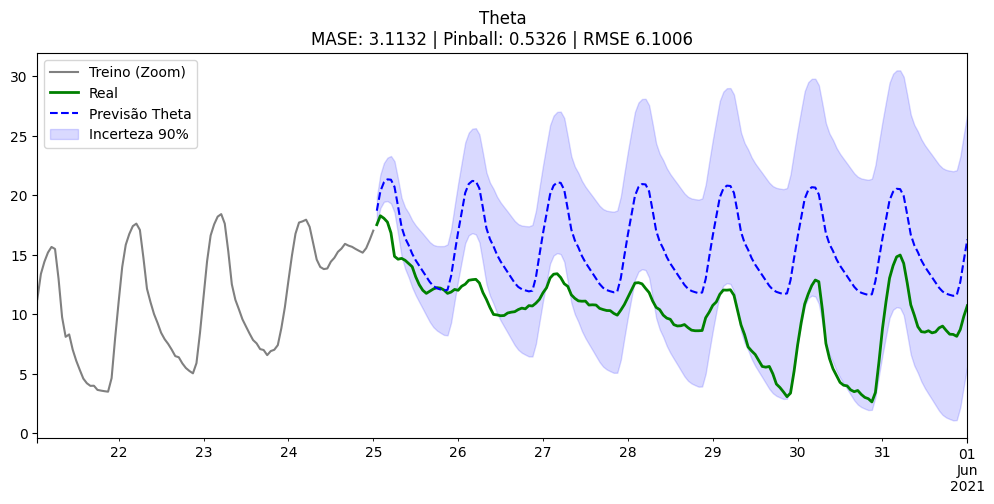

In [ ]:
plt.figure(figsize=(12, 5))
y_treino.iloc[-96:].plot(label='Treino (Zoom)', color='gray')
y_teste.plot(label='Real', color='green', linewidth=2)
y_pred.plot(label='Previsão Theta', color='blue', linestyle='--')
plt.fill_between(intervalos.index,
                 intervalos[(y_treino.name, 0.9, 'lower')],
                 intervalos[(y_treino.name, 0.9, 'upper')],
                 color='blue', alpha=0.15, label='Incerteza 90%')
plt.title(f'Theta\nMASE: {mase:.4f} | Pinball: {pinball:.4f} | RMSE {rmse:.4f}')
plt.legend()
plt.show()

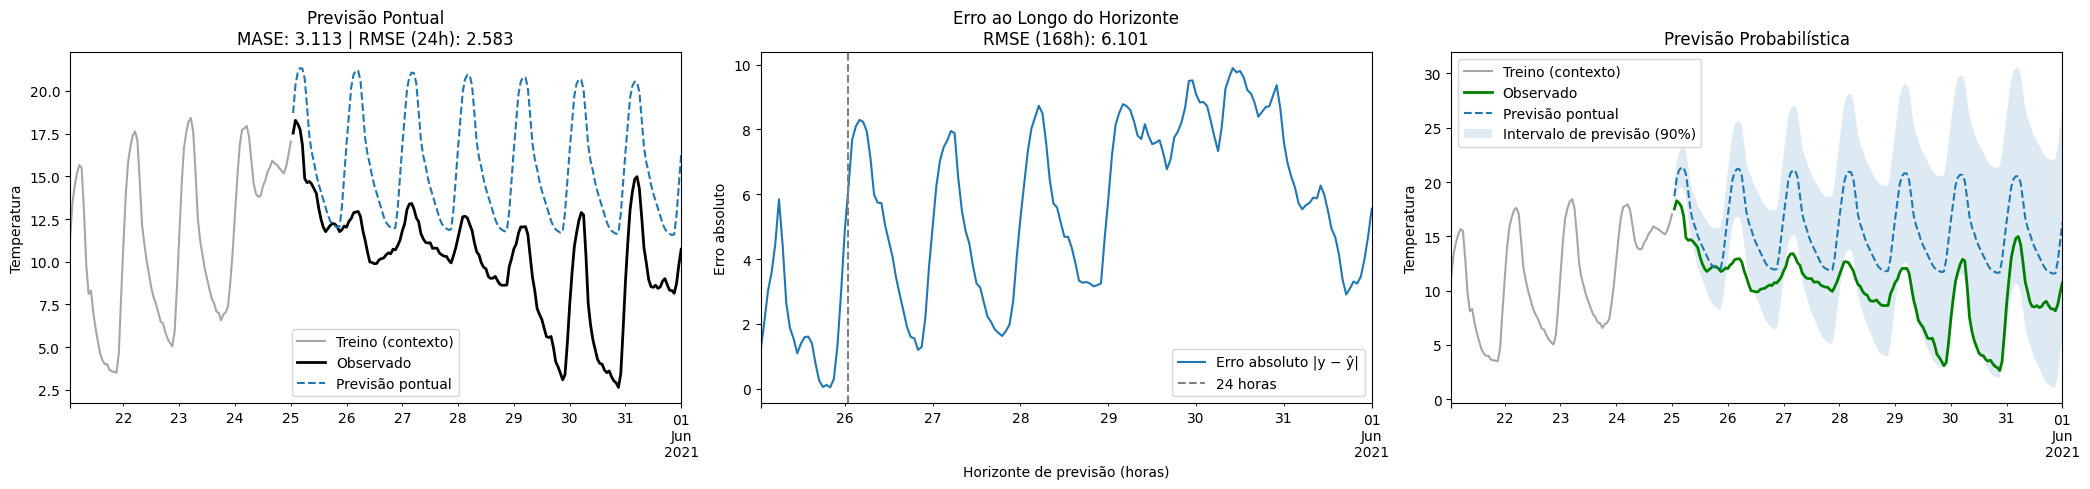

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))

# previsão pontual
y_treino.iloc[-96:].plot(
    ax=axes[0],
    label="Treino (contexto)",
    color="gray",
    alpha=0.7
)

y_teste.plot(
    ax=axes[0],
    label="Observado",
    color="black",
    linewidth=2
)

y_pred.plot(
    ax=axes[0],
    label="Previsão pontual",
    linestyle="--"
)

axes[0].set_title(
    "Previsão Pontual\n"
    f"MASE: {mase:.3f} | RMSE (24h): {rmse_24:.3f}"
)

axes[0].set_ylabel("Temperatura")
axes[0].legend(loc="best")


# erro absoluto por horizonte

erro_abs.plot(
    ax=axes[1],
    label="Erro absoluto |y − ŷ|"
)

axes[1].axvline(
    y_teste.index[24],
    linestyle="--",
    color="gray",
    label="24 horas"
)

axes[1].set_title(
    "Erro ao Longo do Horizonte\n"
    f"RMSE (168h): {rmse_168:.3f}"
)

axes[1].set_ylabel("Erro absoluto")
axes[1].set_xlabel("Horizonte de previsão (horas)")
axes[1].legend(loc="best")

# previsão probabilística
y_treino.iloc[-96:].plot(
    ax=axes[2],
    label="Treino (contexto)",
    color="gray",
    alpha=0.7
)

y_teste.plot(
    ax=axes[2],
    label="Observado",
    color="green",
    linewidth=2
)

y_pred.plot(
    ax=axes[2],
    label="Previsão pontual",
    linestyle="--"
)

axes[2].fill_between(
    intervalos.index,
    intervalos[(y_treino.name, 0.9, "lower")],
    intervalos[(y_treino.name, 0.9, "upper")],
    alpha=0.15,
    label="Intervalo de previsão (90%)"
)

axes[2].set_title("Previsão Probabilística")
axes[2].set_ylabel("Temperatura")
axes[2].legend(loc="best")

plt.tight_layout()
plt.show()


AutoARIMA

In [ ]:
modelo = modelos['AutoARIMA']
modelo.fit(y_treino)

y_pred = modelo.predict(fh)
intervalos = modelo.predict_interval(fh, coverage=0.9)

mase = metrica_mase(y_true=y_teste, y_pred=y_pred, y_train=y_treino)
rmse = metrica_rmse(y_true=y_teste, y_pred=y_pred)
pinball = None
try:
    pinball = metrica_pinball(y_true=y_teste, y_pred=intervalos)
except:
    pinball = np.nan

erro_abs = (y_teste - y_pred).abs()

rmse_24 = MeanSquaredError(square_root=True)(
    y_true=y_teste.iloc[:24],
    y_pred=y_pred.iloc[:24]
)

rmse_168 = MeanSquaredError(square_root=True)(
    y_true=y_teste,
    y_pred=y_pred
)

# salvando resultados
preds_modelos['AutoARIMA'] = y_pred
intervalos_modelos['AutoARIMA'] = intervalos
resultados_modelos['AutoARIMA'] = {
    'MASE': mase,
    'RMSE': rmse,
    'RMSE_24h': rmse_24,
    'RMSE_168h': rmse_168,
    'Pinball_90': pinball
}

print(f'{'AutoARIMA':<20} | MASE {mase:.4f} | Pinball {pinball:.4f} | RMSE {rmse:.4f}')

AutoARIMA            | MASE 4.5547 | Pinball 0.9326 | RMSE 8.8548


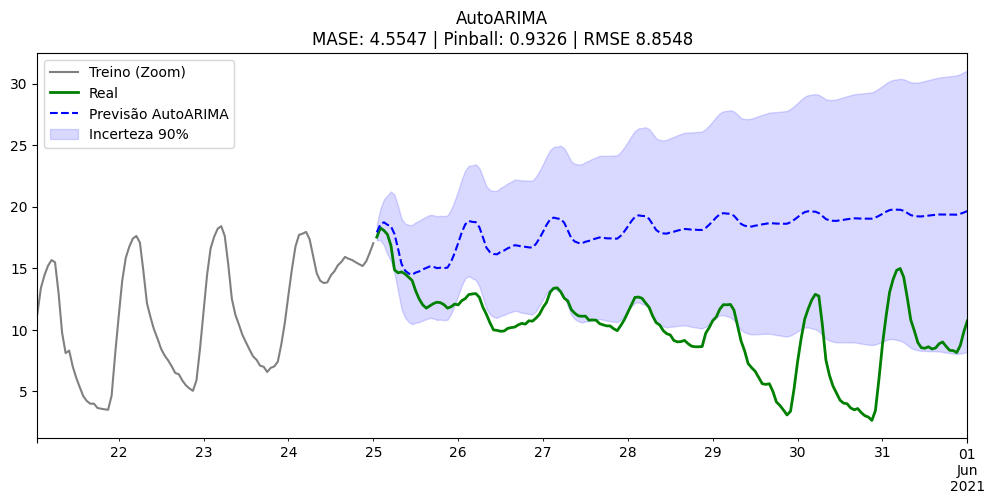

In [ ]:
plt.figure(figsize=(12, 5))
y_treino.iloc[-96:].plot(label='Treino (Zoom)', color='gray')
y_teste.plot(label='Real', color='green', linewidth=2)
y_pred.plot(label='Previsão AutoARIMA', color='blue', linestyle='--')
plt.fill_between(intervalos.index,
                 intervalos[(y_treino.name, 0.9, 'lower')],
                 intervalos[(y_treino.name, 0.9, 'upper')],
                 color='blue', alpha=0.15, label='Incerteza 90%')
plt.title(f'AutoARIMA\nMASE: {mase:.4f} | Pinball: {pinball:.4f} | RMSE {rmse:.4f}')
plt.legend()
plt.show()

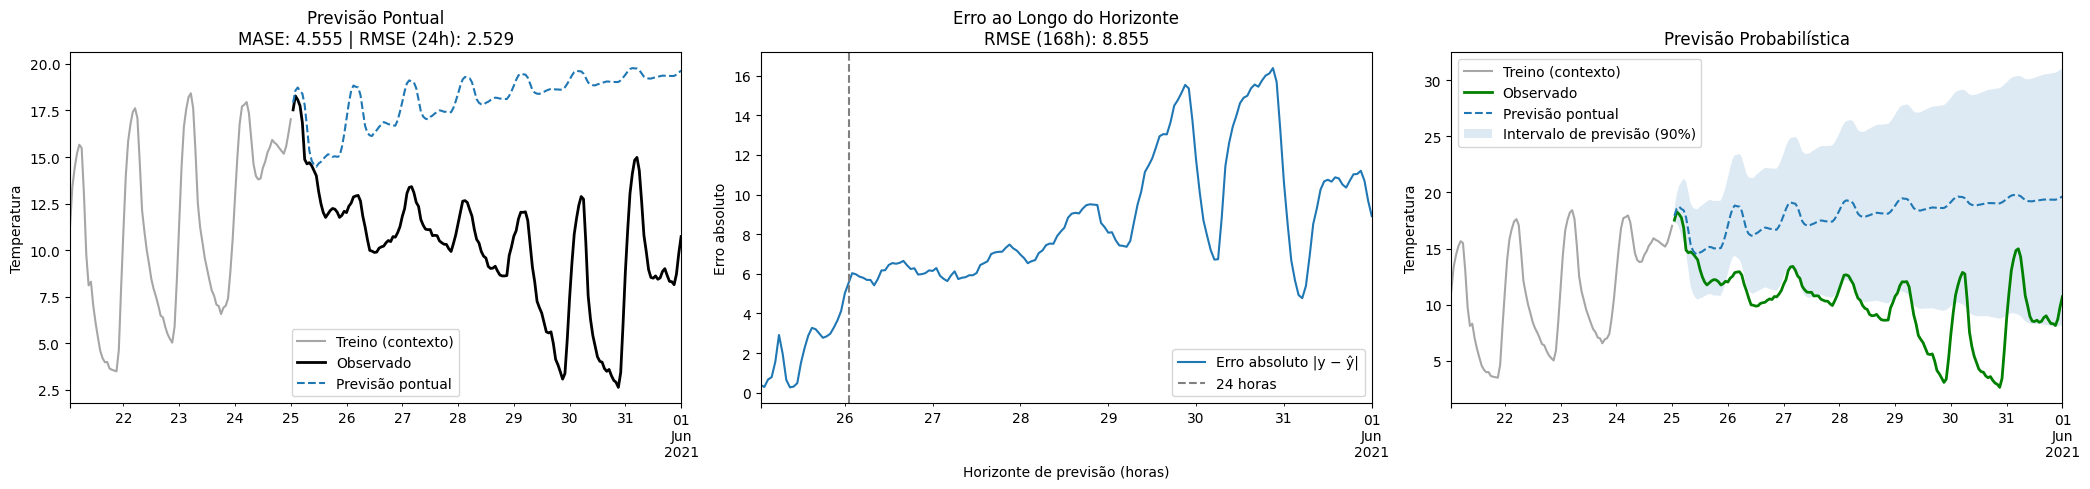

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))

# previsão pontual
y_treino.iloc[-96:].plot(
    ax=axes[0],
    label="Treino (contexto)",
    color="gray",
    alpha=0.7
)

y_teste.plot(
    ax=axes[0],
    label="Observado",
    color="black",
    linewidth=2
)

y_pred.plot(
    ax=axes[0],
    label="Previsão pontual",
    linestyle="--"
)

axes[0].set_title(
    "Previsão Pontual\n"
    f"MASE: {mase:.3f} | RMSE (24h): {rmse_24:.3f}"
)

axes[0].set_ylabel("Temperatura")
axes[0].legend(loc="best")


# erro absoluto por horizonte

erro_abs.plot(
    ax=axes[1],
    label="Erro absoluto |y − ŷ|"
)

axes[1].axvline(
    y_teste.index[24],
    linestyle="--",
    color="gray",
    label="24 horas"
)



axes[1].set_title(
    "Erro ao Longo do Horizonte\n"
    f"RMSE (168h): {rmse_168:.3f}"
)

axes[1].set_ylabel("Erro absoluto")
axes[1].set_xlabel("Horizonte de previsão (horas)")
axes[1].legend(loc="best")

# previsão probabilística
y_treino.iloc[-96:].plot(
    ax=axes[2],
    label="Treino (contexto)",
    color="gray",
    alpha=0.7
)

y_teste.plot(
    ax=axes[2],
    label="Observado",
    color="green",
    linewidth=2
)

y_pred.plot(
    ax=axes[2],
    label="Previsão pontual",
    linestyle="--"
)

axes[2].fill_between(
    intervalos.index,
    intervalos[(y_treino.name, 0.9, "lower")],
    intervalos[(y_treino.name, 0.9, "upper")],
    alpha=0.15,
    label="Intervalo de previsão (90%)"
)

axes[2].set_title("Previsão Probabilística")
axes[2].set_ylabel("Temperatura")
axes[2].legend(loc="best")

plt.tight_layout()
plt.show()

Prophet

In [ ]:
modelo = modelos['Prophet']
modelo.fit(y_treino)

y_pred = modelo.predict(fh)
intervalos = modelo.predict_interval(fh, coverage=0.9)


mase = metrica_mase(y_true=y_teste, y_pred=y_pred, y_train=y_treino)
rmse = metrica_rmse(y_true=y_teste, y_pred=y_pred)
pinball = None
try:
    pinball = metrica_pinball(y_true=y_teste, y_pred=intervalos)
except:
    pinball = np.nan

erro_abs = (y_teste - y_pred).abs()

rmse_24 = MeanSquaredError(square_root=True)(
    y_true=y_teste.iloc[:24],
    y_pred=y_pred.iloc[:24]
)

rmse_168 = MeanSquaredError(square_root=True)(
    y_true=y_teste,
    y_pred=y_pred
)

# salvando resultados
preds_modelos['Prophet'] = y_pred
intervalos_modelos['Prophet'] = intervalos
resultados_modelos['Prophet'] = {
    'MASE': mase,
    'RMSE': rmse,
    'RMSE_24h': rmse_24,
    'RMSE_168h': rmse_168,
    'Pinball_90': pinball
}

print(f'{'Prophet':<20} | MASE {mase:.4f} | Pinball {pinball:.4f} | RMSE {rmse:.4f}')

Prophet              | MASE 1.6830 | Pinball 0.5566 | RMSE 3.6975


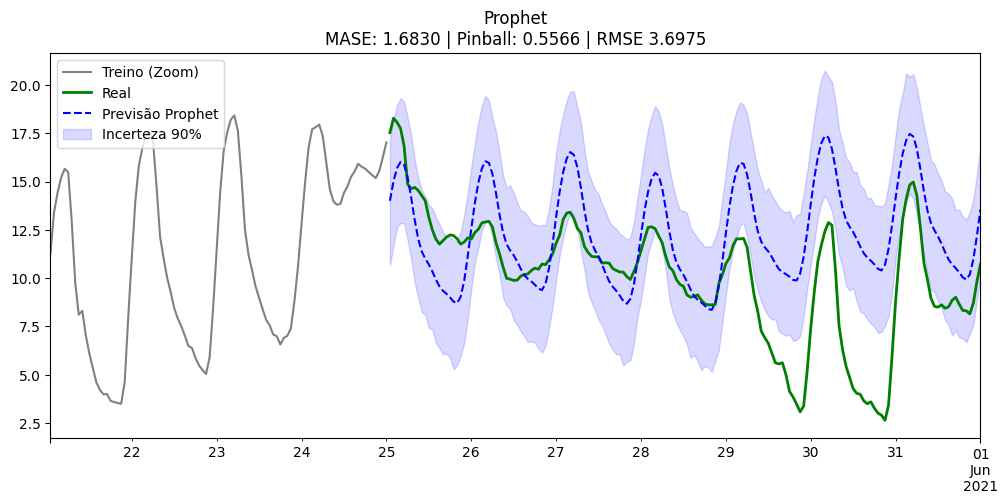

In [ ]:
plt.figure(figsize=(12, 5))
y_treino.iloc[-96:].plot(label='Treino (Zoom)', color='gray')
y_teste.plot(label='Real', color='green', linewidth=2)
y_pred.plot(label='Previsão Prophet', color='blue', linestyle='--')
plt.fill_between(intervalos.index,
                 intervalos[(y_treino.name, 0.9, 'lower')],
                 intervalos[(y_treino.name, 0.9, 'upper')],
                 color='blue', alpha=0.15, label='Incerteza 90%')
plt.title(f'Prophet\nMASE: {mase:.4f} | Pinball: {pinball:.4f} | RMSE {rmse:.4f}')
plt.legend()
plt.show()

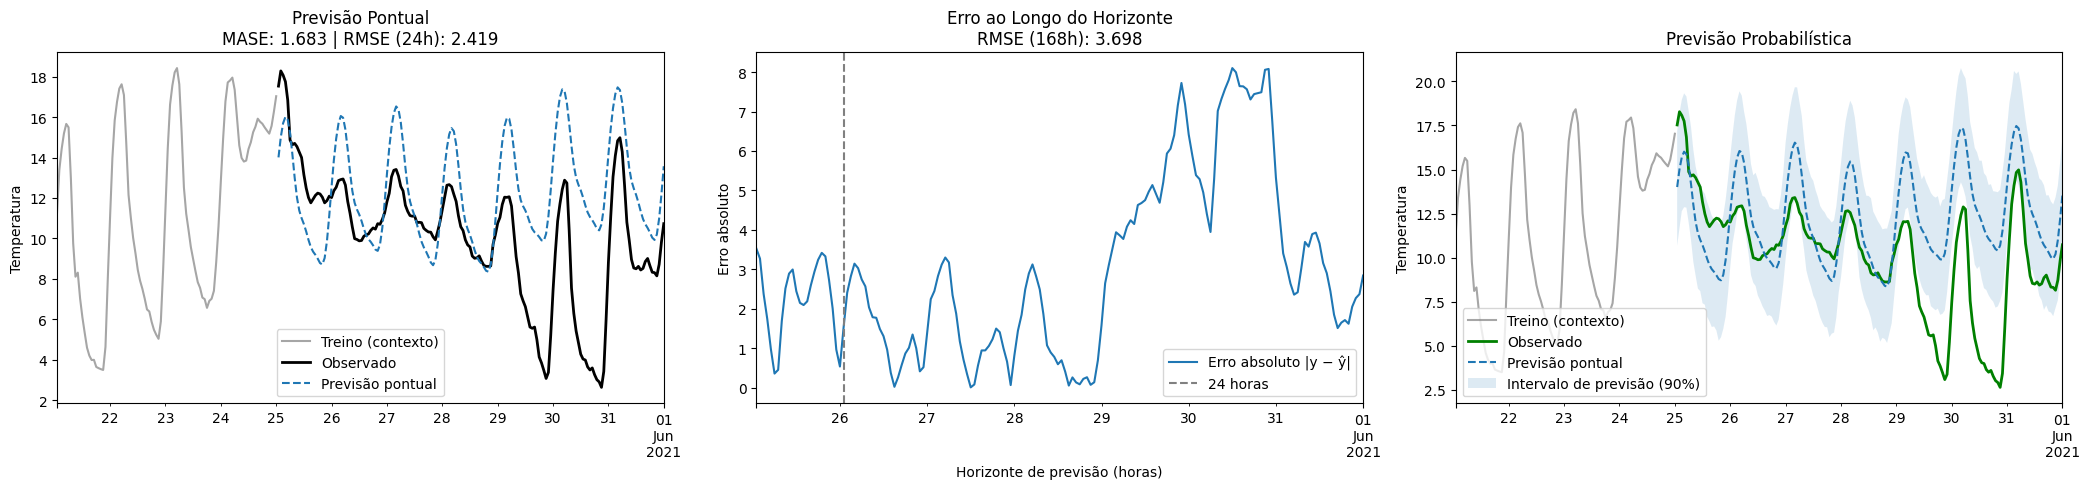

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))

# previsão pontual
y_treino.iloc[-96:].plot(
    ax=axes[0],
    label="Treino (contexto)",
    color="gray",
    alpha=0.7
)

y_teste.plot(
    ax=axes[0],
    label="Observado",
    color="black",
    linewidth=2
)

y_pred.plot(
    ax=axes[0],
    label="Previsão pontual",
    linestyle="--"
)

axes[0].set_title(
    "Previsão Pontual\n"
    f"MASE: {mase:.3f} | RMSE (24h): {rmse_24:.3f}"
)

axes[0].set_ylabel("Temperatura")
axes[0].legend(loc="best")


# erro absoluto por horizonte

erro_abs.plot(
    ax=axes[1],
    label="Erro absoluto |y − ŷ|"
)

axes[1].axvline(
    y_teste.index[24],
    linestyle="--",
    color="gray",
    label="24 horas"
)



axes[1].set_title(
    "Erro ao Longo do Horizonte\n"
    f"RMSE (168h): {rmse_168:.3f}"
)

axes[1].set_ylabel("Erro absoluto")
axes[1].set_xlabel("Horizonte de previsão (horas)")
axes[1].legend(loc="best")

# previsão probabilística
y_treino.iloc[-96:].plot(
    ax=axes[2],
    label="Treino (contexto)",
    color="gray",
    alpha=0.7
)

y_teste.plot(
    ax=axes[2],
    label="Observado",
    color="green",
    linewidth=2
)

y_pred.plot(
    ax=axes[2],
    label="Previsão pontual",
    linestyle="--"
)

axes[2].fill_between(
    intervalos.index,
    intervalos[(y_treino.name, 0.9, "lower")],
    intervalos[(y_treino.name, 0.9, "upper")],
    alpha=0.15,
    label="Intervalo de previsão (90%)"
)

axes[2].set_title("Previsão Probabilística")
axes[2].set_ylabel("Temperatura")
axes[2].legend(loc="best")

plt.tight_layout()
plt.show()

ExpSmoothing + Var

In [ ]:
modelo = modelos['ExpSmoothing + Var']
modelo.fit(y_treino)

y_pred = modelo.predict(fh)

intervalos = modelo.predict_interval(fh, coverage=0.9)

mase = metrica_mase(y_true=y_teste, y_pred=y_pred, y_train=y_treino)
rmse = metrica_rmse(y_true=y_teste, y_pred=y_pred)
pinball = None
try:
    pinball = metrica_pinball(y_true=y_teste, y_pred=intervalos)
except:
    pinball = np.nan


erro_abs = (y_teste - y_pred).abs()

rmse_24 = MeanSquaredError(square_root=True)(
    y_true=y_teste.iloc[:24],
    y_pred=y_pred.iloc[:24]
)

rmse_168 = MeanSquaredError(square_root=True)(
    y_true=y_teste,
    y_pred=y_pred
)

# salvando resultados
preds_modelos['ExpSmoothing + Var'] = y_pred
intervalos_modelos['ExpSmoothing + Var'] = intervalos
resultados_modelos['ExpSmoothing + Var'] = {
    'MASE': mase,
    'RMSE': rmse,
    'RMSE_24h': rmse_24,
    'RMSE_168h': rmse_168,
    'Pinball_90': pinball
}

print(f'{'ExpSmoothing + Var':<20} | MASE {mase:.4f} | Pinball {pinball:.4f} | RMSE {rmse:.4f}')

ExpSmoothing + Var   | MASE 3.4893 | Pinball 1.0894 | RMSE 6.6475


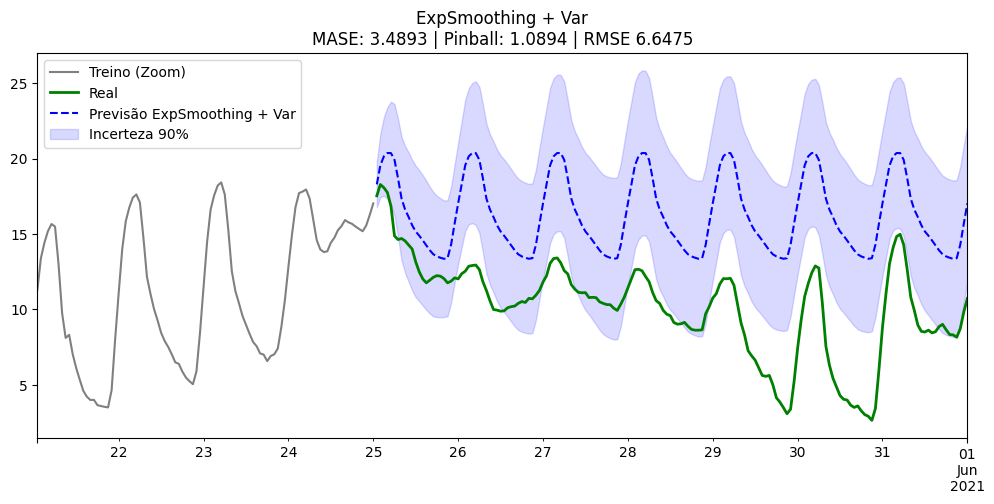

In [ ]:
plt.figure(figsize=(12, 5))
y_treino.iloc[-96:].plot(label='Treino (Zoom)', color='gray')
y_teste.plot(label='Real', color='green', linewidth=2)
y_pred.plot(label='Previsão ExpSmoothing + Var', color='blue', linestyle='--')
plt.fill_between(intervalos.index,
                 intervalos[(y_treino.name, 0.9, 'lower')],
                 intervalos[(y_treino.name, 0.9, 'upper')],
                 color='blue', alpha=0.15, label='Incerteza 90%')
plt.title(f'ExpSmoothing + Var\nMASE: {mase:.4f} | Pinball: {pinball:.4f} | RMSE {rmse:.4f}')
plt.legend()
plt.show()

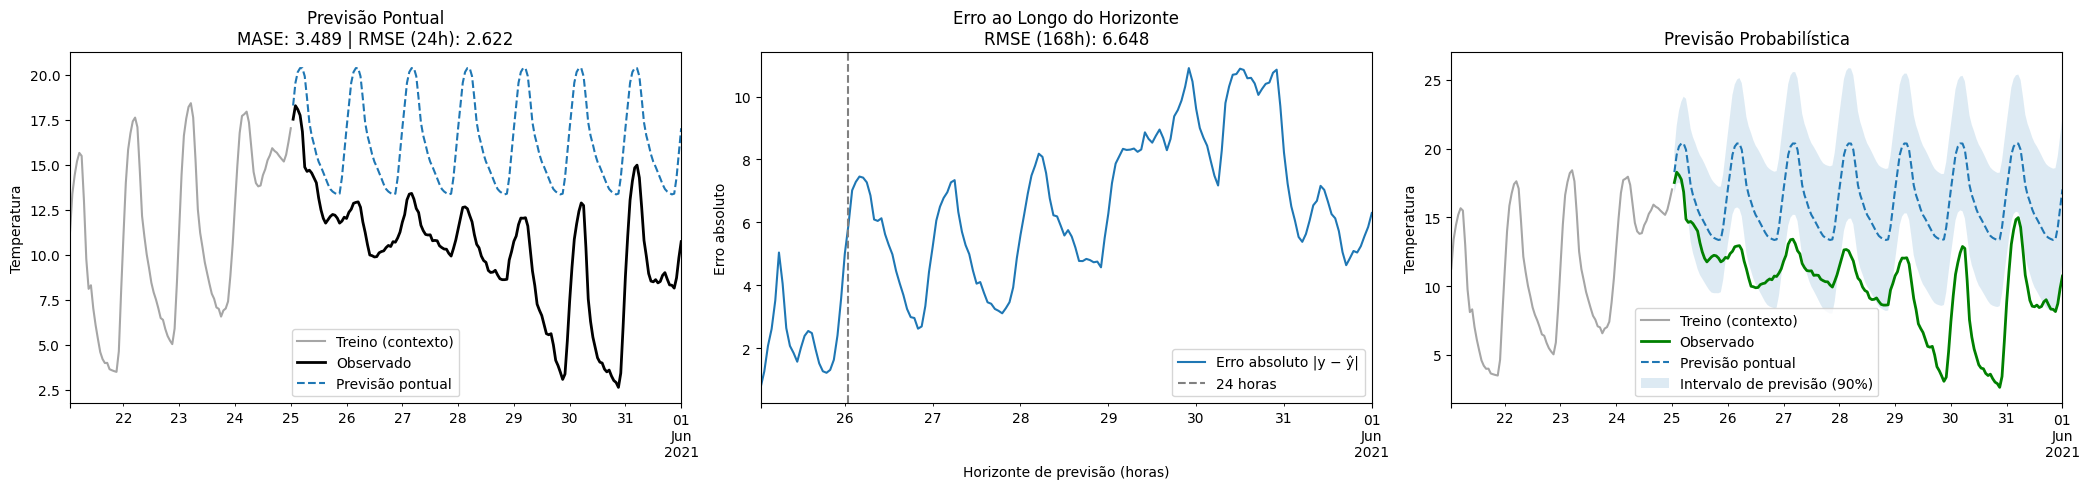

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))

# previsão pontual
y_treino.iloc[-96:].plot(
    ax=axes[0],
    label="Treino (contexto)",
    color="gray",
    alpha=0.7
)

y_teste.plot(
    ax=axes[0],
    label="Observado",
    color="black",
    linewidth=2
)

y_pred.plot(
    ax=axes[0],
    label="Previsão pontual",
    linestyle="--"
)

axes[0].set_title(
    "Previsão Pontual\n"
    f"MASE: {mase:.3f} | RMSE (24h): {rmse_24:.3f}"
)

axes[0].set_ylabel("Temperatura")
axes[0].legend(loc="best")


# erro absoluto por horizonte

erro_abs.plot(
    ax=axes[1],
    label="Erro absoluto |y − ŷ|"
)

axes[1].axvline(
    y_teste.index[24],
    linestyle="--",
    color="gray",
    label="24 horas"
)



axes[1].set_title(
    "Erro ao Longo do Horizonte\n"
    f"RMSE (168h): {rmse_168:.3f}"
)

axes[1].set_ylabel("Erro absoluto")
axes[1].set_xlabel("Horizonte de previsão (horas)")
axes[1].legend(loc="best")

# previsão probabilística
y_treino.iloc[-96:].plot(
    ax=axes[2],
    label="Treino (contexto)",
    color="gray",
    alpha=0.7
)

y_teste.plot(
    ax=axes[2],
    label="Observado",
    color="green",
    linewidth=2
)

y_pred.plot(
    ax=axes[2],
    label="Previsão pontual",
    linestyle="--"
)

axes[2].fill_between(
    intervalos.index,
    intervalos[(y_treino.name, 0.9, "lower")],
    intervalos[(y_treino.name, 0.9, "upper")],
    alpha=0.15,
    label="Intervalo de previsão (90%)"
)

axes[2].set_title("Previsão Probabilística")
axes[2].set_ylabel("Temperatura")
axes[2].legend(loc="best")

plt.tight_layout()
plt.show()

# Comparação de resultados

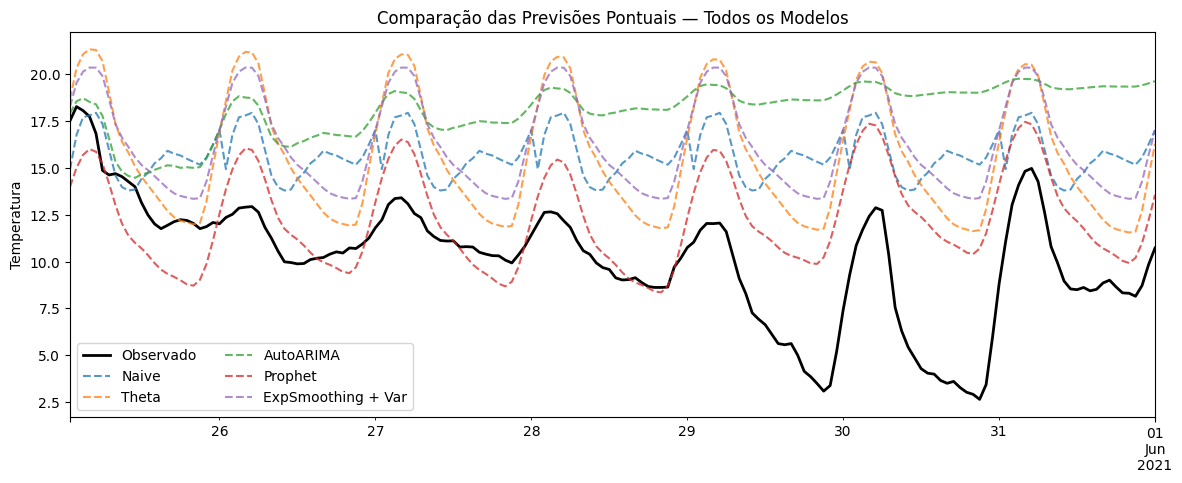

In [ ]:
# gráfico comparativo
plt.figure(figsize=(14, 5))

# série real
y_teste.plot(
    label="Observado",
    color="black",
    linewidth=2
)

# previsões dos modelos
for nome, y_pred in preds_modelos.items():
    y_pred.plot(
        label=nome,
        linestyle="--",
        alpha=0.75
    )

plt.title('Comparação das Previsões Pontuais — Todos os Modelos')
plt.ylabel('Temperatura')
plt.legend(ncol=2)
plt.show()



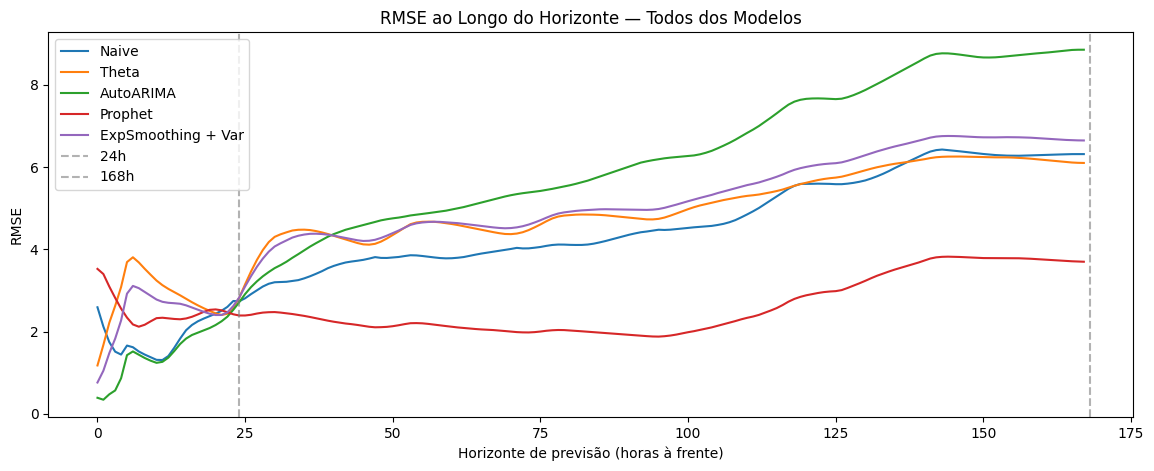

In [ ]:
# rmse por horizonte
plt.figure(figsize=(14, 5))

for nome, y_pred in preds_modelos.items():
    erros = (y_teste.values - y_pred.values)
    rmse_h = [
        np.sqrt(np.mean(erros[:h] ** 2))
        for h in range(1, len(erros) + 1)
    ]
    plt.plot(rmse_h, label=nome)

plt.axvline(24, linestyle='--', color='gray', alpha=0.6, label='24h')
plt.axvline(168, linestyle='--', color='gray', alpha=0.6, label='168h')

plt.title('RMSE ao Longo do Horizonte — Todos dos Modelos')
plt.xlabel('Horizonte de previsão (horas à frente)')
plt.ylabel('RMSE')
plt.legend()
plt.show()


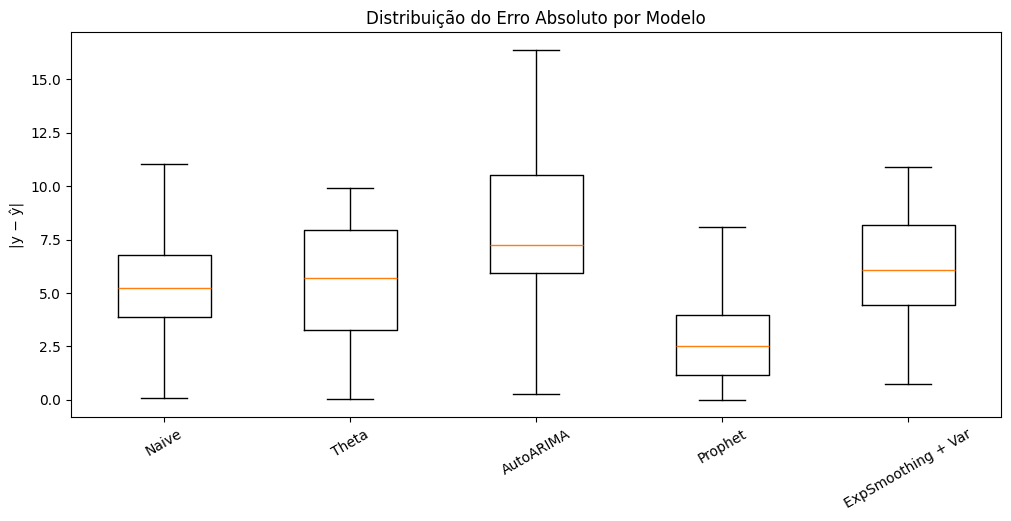

In [ ]:
# DISTRIBUIÇÃO DO ERRO

dados_erro = [
    np.abs(y_teste - preds_modelos[nome])
    for nome in preds_modelos
]

plt.figure(figsize=(12, 5))
plt.boxplot(
    dados_erro,
    labels=preds_modelos.keys(),
    showfliers=False
)

plt.title('Distribuição do Erro Absoluto por Modelo')
plt.ylabel('|y − ŷ|')
plt.xticks(rotation=30)
plt.show()


Resultados finais

In [ ]:
tabela_metricas = pd.DataFrame(resultados_modelos).T
tabela_metricas


,MASE,RMSE,RMSE_24h,RMSE_168h,Pinball_90
Naive,3.214940,6.315886,2.742330,6.315886,0.533362
Theta,3.113154,6.100577,2.582621,6.100577,0.532578
AutoARIMA,4.554732,8.854844,2.528877,8.854844,0.932560
Prophet,1.682967,3.697530,2.419183,3.697530,0.556604
ExpSmoothing + Var,3.489308,6.647547,2.621525,6.647547,1.089388


Ranking Final

In [ ]:
ranking = tabela_metricas.rank(ascending=True)
ranking["Ranking médio"] = ranking.mean(axis=1)
ranking.sort_values("Ranking médio")


,MASE,RMSE,RMSE_24h,RMSE_168h,Pinball_90,Ranking médio
Prophet,1.0,1.0,1.0,1.0,3.0,1.4
Theta,2.0,2.0,3.0,2.0,1.0,2.0
Naive,3.0,3.0,5.0,3.0,2.0,3.2
AutoARIMA,5.0,5.0,2.0,5.0,4.0,4.2
ExpSmoothing + Var,4.0,4.0,4.0,4.0,5.0,4.2


# Gráficos e análise: https://docs.google.com/document/d/170svw44iETsqEQILLOqOGLDlcU4hRXW-8qUM0E7XZMU/edit?usp=sharing